# HarmonyRL demo

Write chords under a melody, redraw the bars you choose, and fill bars of a lead sheet that
already has chords.

The cells that display scores and audio call [MuseScore 4](https://musescore.org) to render
them; set `MUSESCORE` to its command on your machine. HarmonyRL itself needs only
`pip install harmonyrl`.

In [1]:
import subprocess
from dataclasses import replace
from pathlib import Path

import music21
from IPython.display import Audio, Image, Markdown

from harmonyrl import HarmonyRL
from harmonyrl.ingest import read_lead_sheet
from harmonyrl.render import write_lead_sheet
from harmonyrl.schema import Key, LeadSheet, Mode, SheetPart

MUSESCORE = "mscore"
OUTPUT = Path("output")


def show(sheet: LeadSheet, name: str) -> None:
	"""Display `sheet` as a score and its audio, both rendered with MuseScore."""
	folder = OUTPUT / name
	folder.mkdir(parents=True, exist_ok=True)
	write_lead_sheet(sheet, folder / "sheet.musicxml")
	write_lead_sheet(sheet, folder / "sheet.mid")

	renders = (
		["-r", "110", "-o", "score.png", "sheet.musicxml"],
		["-b", "64", "-o", "sheet.mp3", "sheet.mid"],
	)
	for args in renders:
		subprocess.run([MUSESCORE, *args], cwd=folder, check=True, capture_output=True)

	for page in sorted(folder.glob("score-*.png")):
		display(Image(filename=page))
	display(Audio(filename=folder / "sheet.mp3"))

## 1. Read a melody

*Jeanie with the Light Brown Hair* (Stephen Foster, 1854) comes with music21 as a lead sheet.
Its key signature has no flats, but the music is in F major, so the key is given with `key=`
(tonic as a pitch class, 0 = C). Here only the melody is kept; its chords come back in step 4.

repeats, endings, and jumps are ignored: the melody is read once as written, and the output has no repeat signs


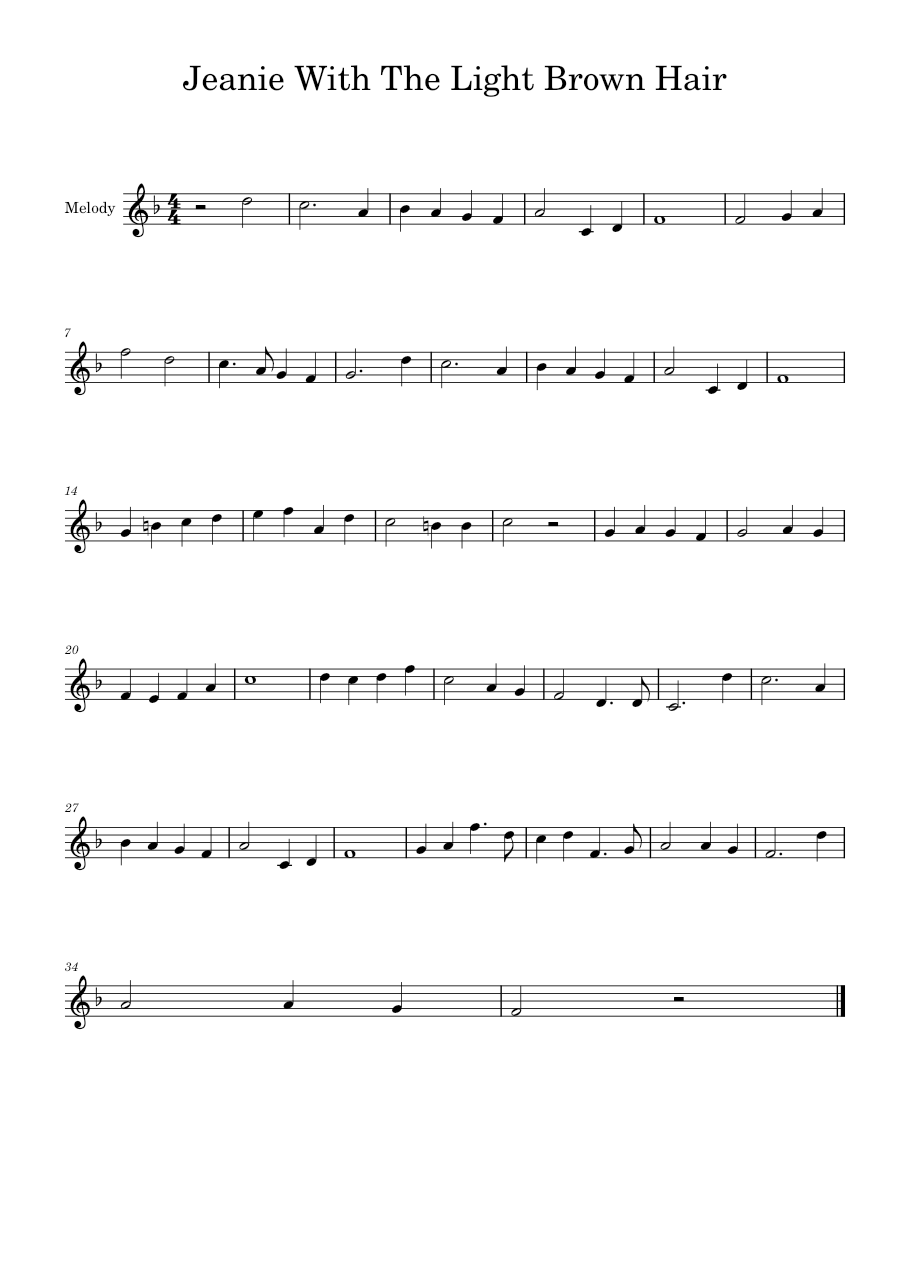

In [2]:
path = Path(music21.corpus.getWork("leadSheet/fosterBrownHair.mxl"))
imported = read_lead_sheet(path, key=Key(5, Mode.MAJOR))
print(*imported.warnings, sep="\n")

original = imported.sheet
melody = replace(original, parts=tuple(SheetPart(part.melody, None) for part in original.parts))
show(melody, "melody")

## 2. Harmonize with each model

The 35 bars are more than 1 call covers (32), so `harmonize_sheet` works in overlapping windows.

### `chromatic`

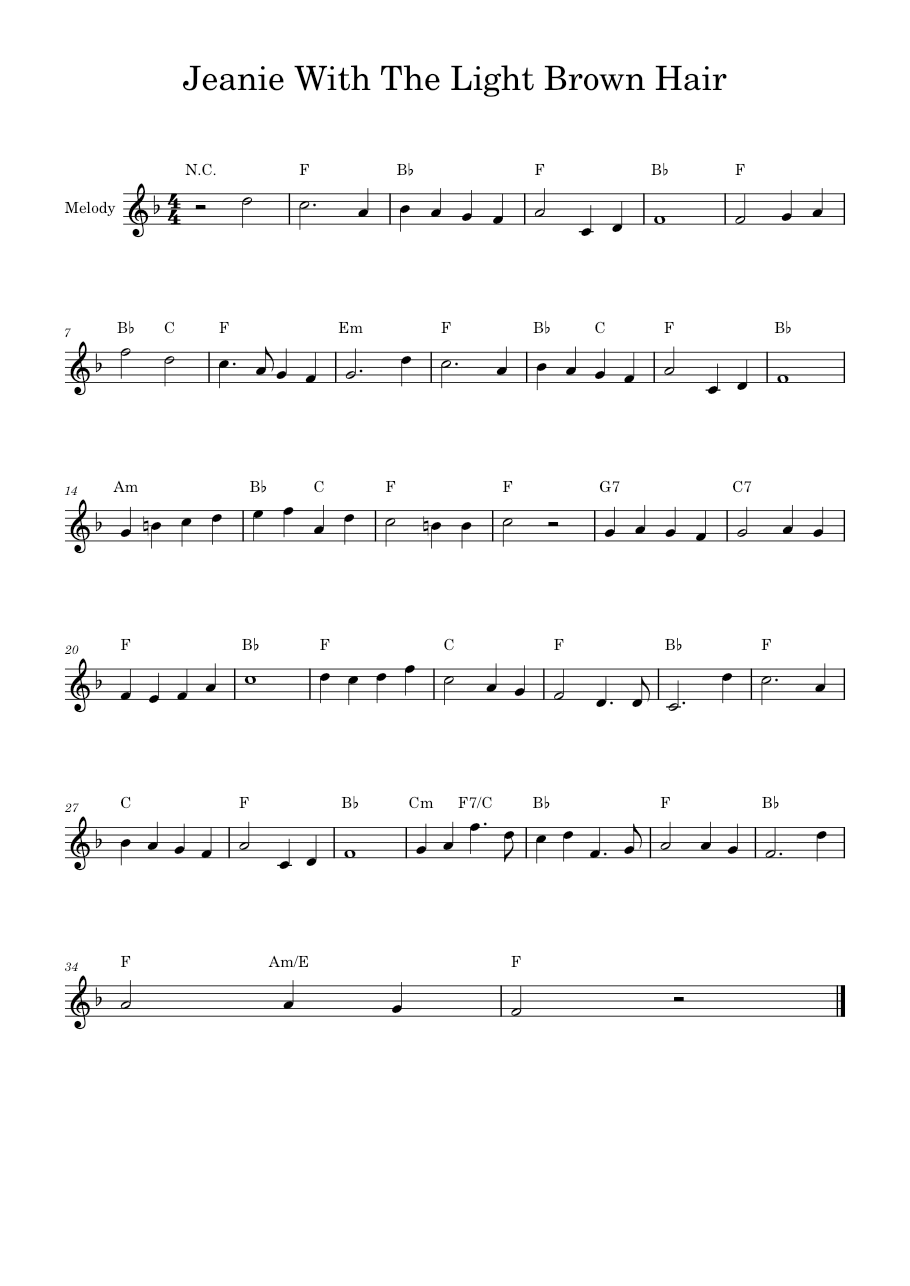

### `smooth`

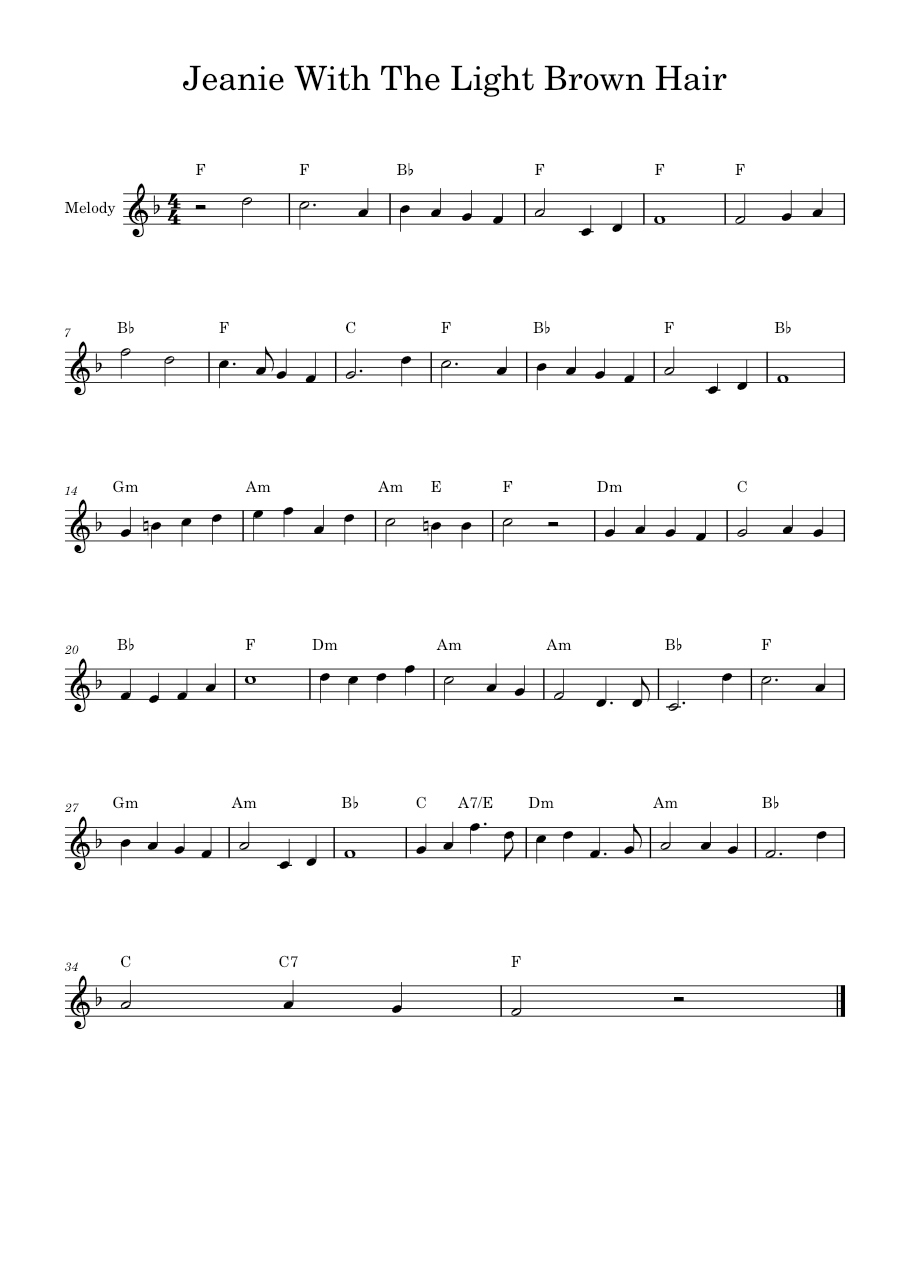

### `base`

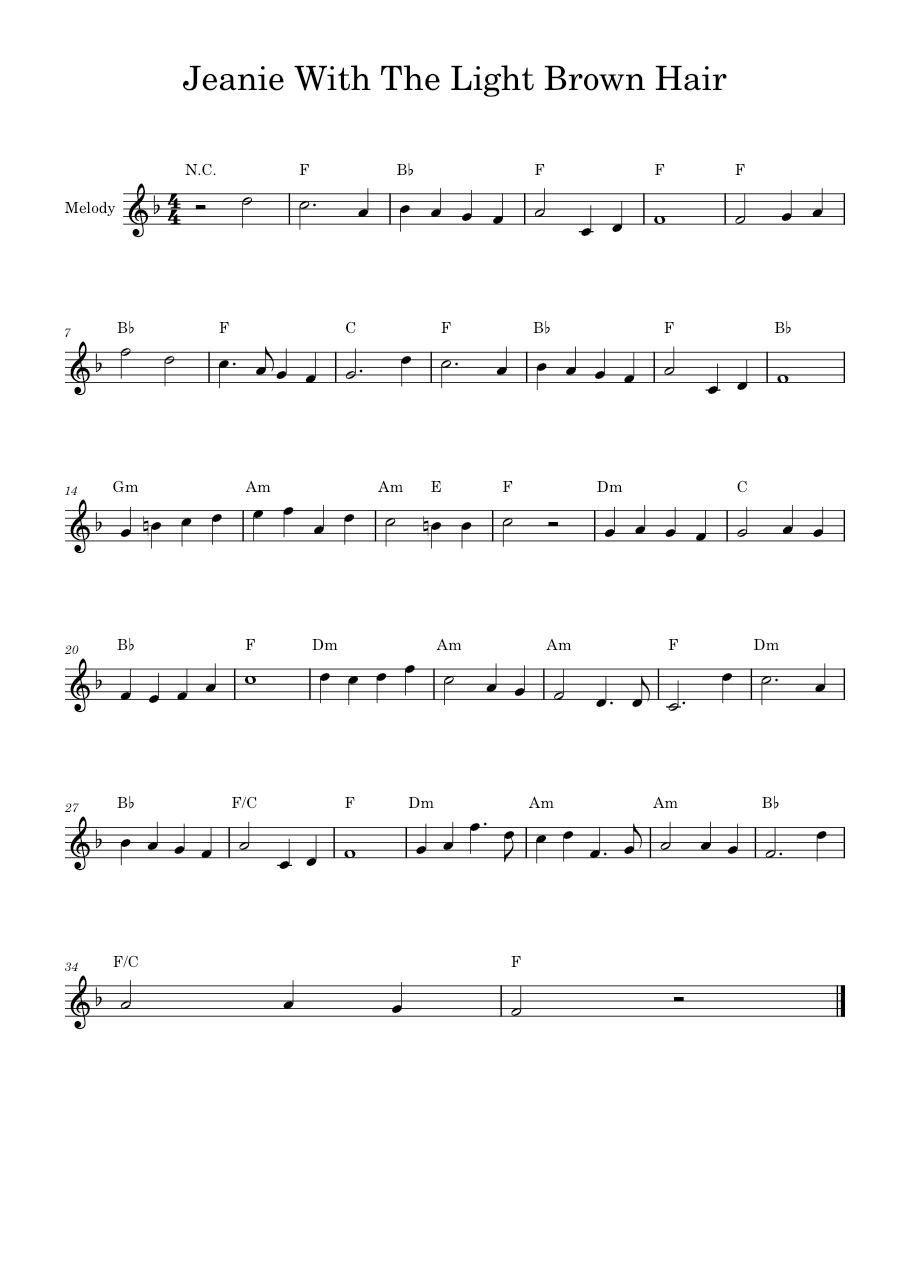

In [3]:
models = {
	name: HarmonyRL.from_pretrained(f"CloudHolic/harmonyrl-{name}")
	for name in ("chromatic", "smooth", "base")
}
harmonized = {}

for name, model in models.items():
	harmonized[name] = model.harmonize_sheet(melody, seed=0)[0]
	display(Markdown(f"### `{name}`"))
	show(harmonized[name], name)

## 3. Redraw 2 bars

`bars=range(8, 10)` counts bars from 0, so it redraws measures 9 and 10 of the score. Every
other chord stays as it was.

### Redraw 1

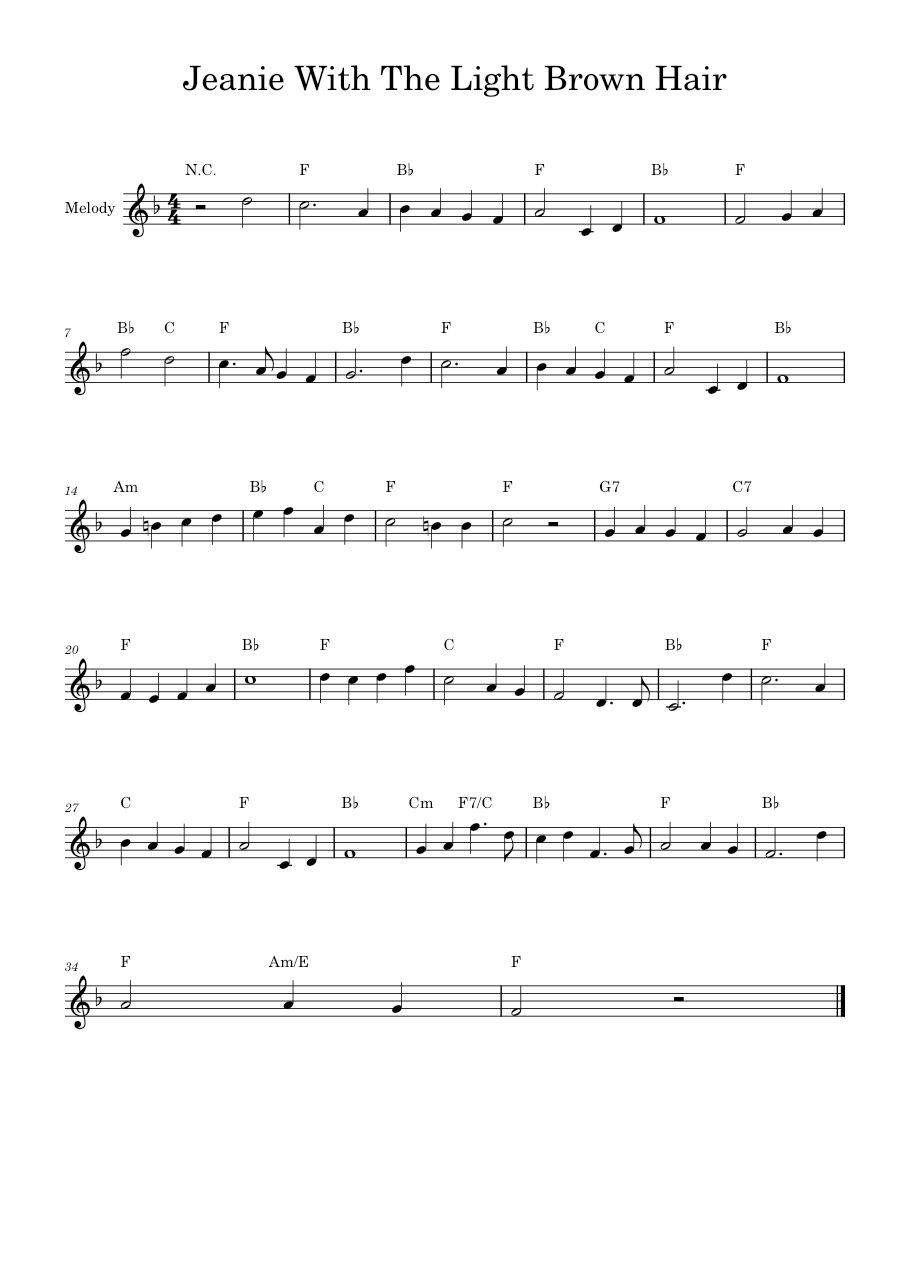

### Redraw 2

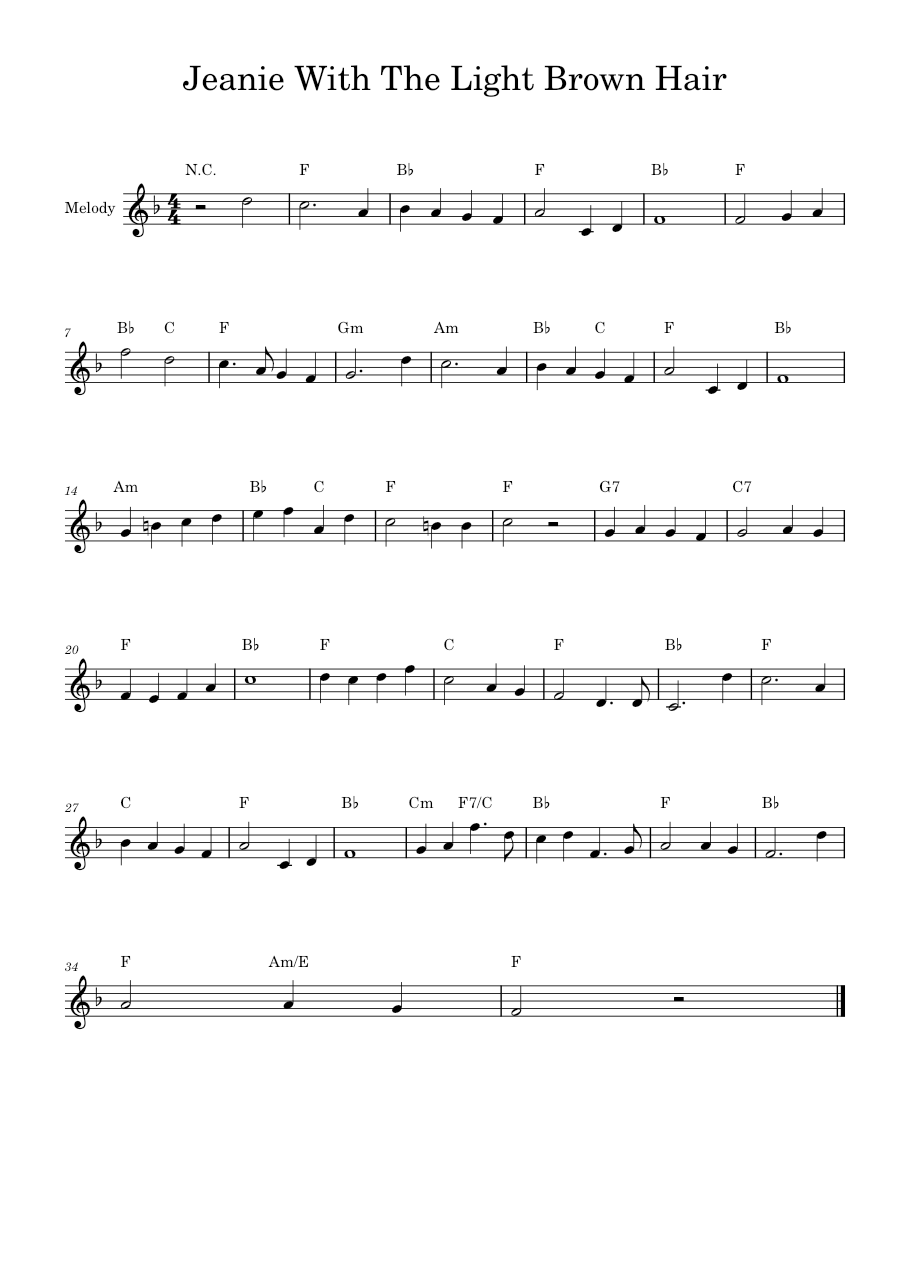

In [4]:
chromatic = models["chromatic"]
redrawn = chromatic.harmonize_sheet(
	harmonized["chromatic"], bars=range(8, 10), candidates=2, seed=1
)

for index, sheet in enumerate(redrawn, 1):
	display(Markdown(f"### Redraw {index}"))
	show(sheet, f"redraw-{index}")

## 4. Fill bars of a lead sheet with chords

The lead sheet as read, with Foster's chords, gets new chords in measures 25–28 only.

### Original

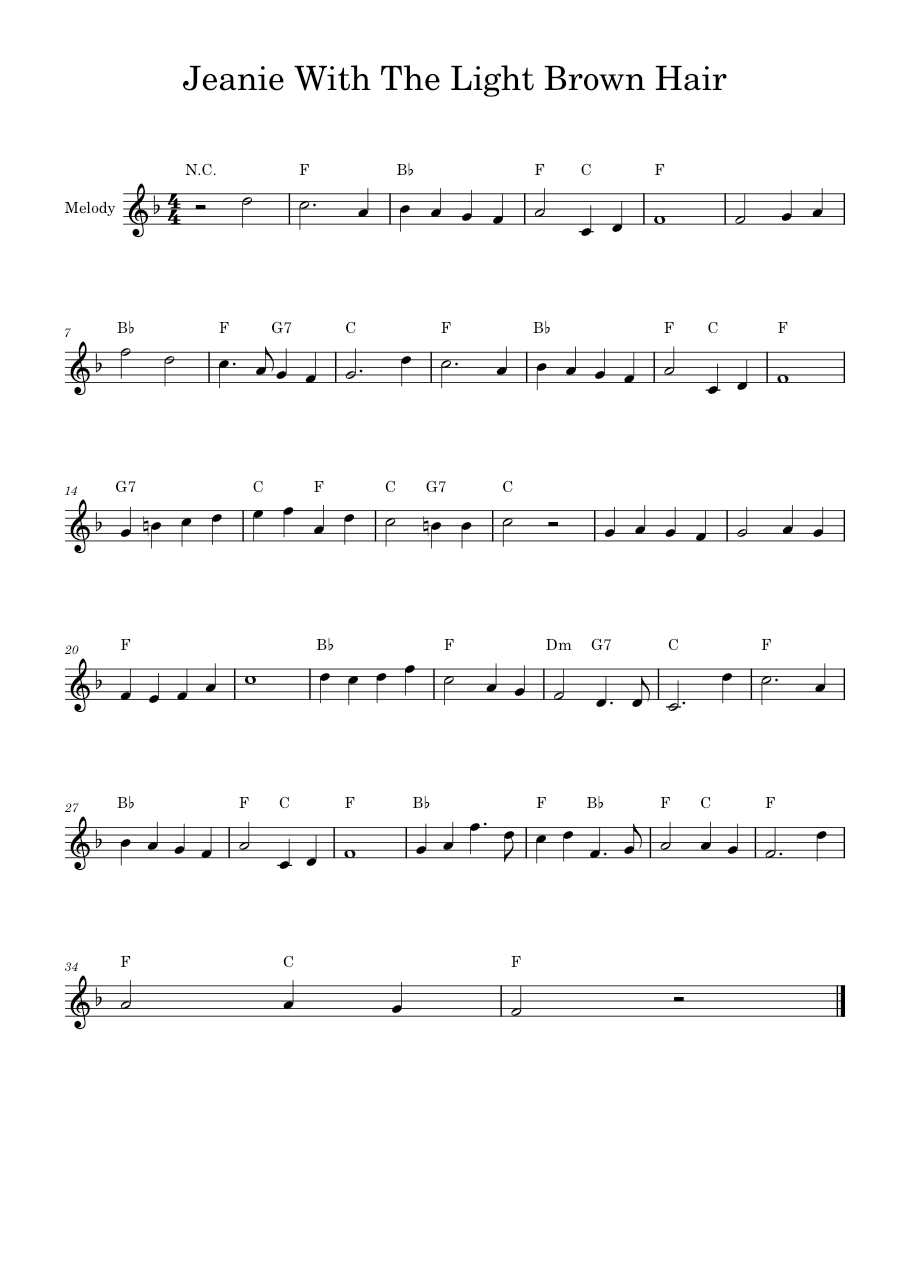

### Filled

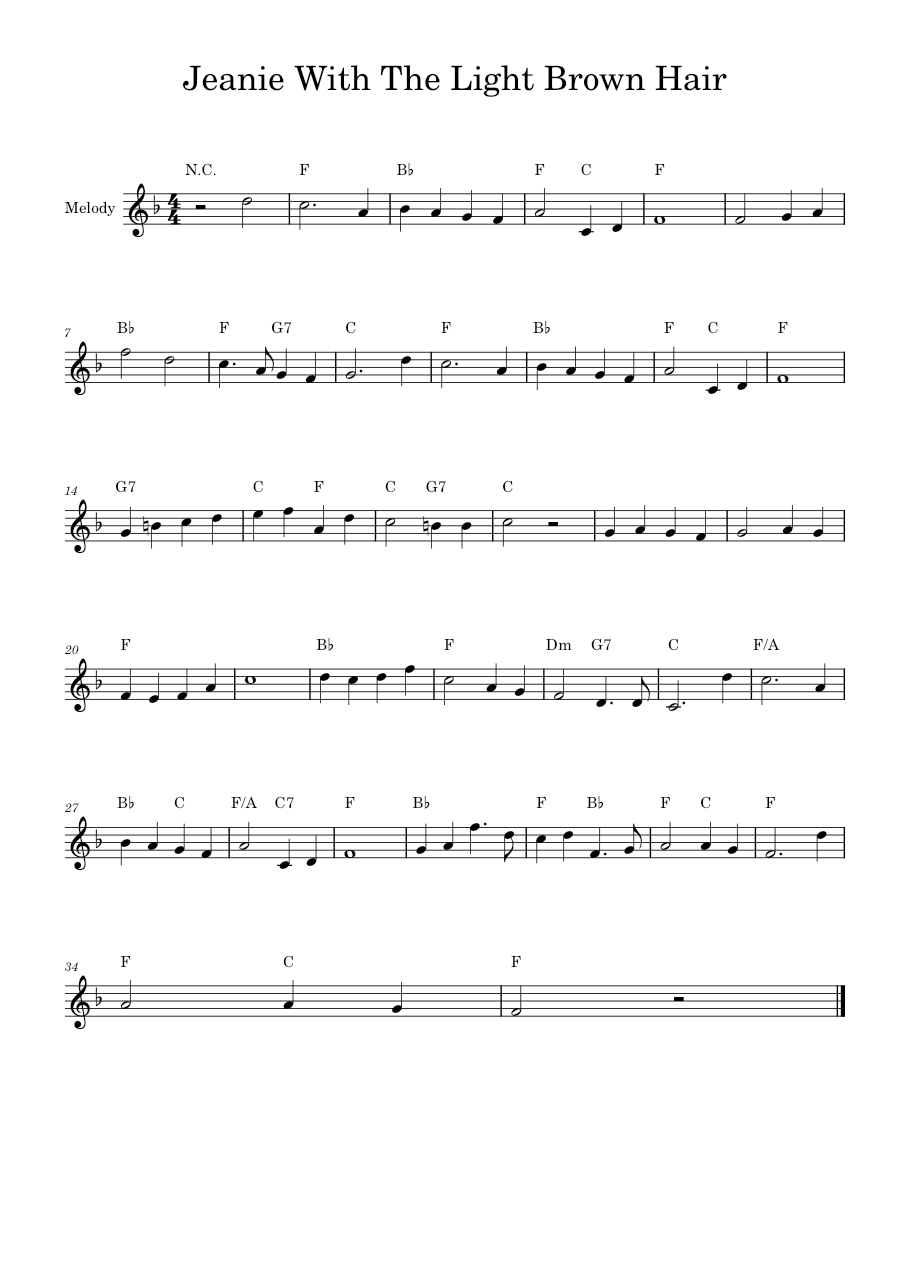

In [5]:
filled = chromatic.harmonize_sheet(original, bars=range(24, 28), seed=2)[0]

display(Markdown("### Original"))
show(original, "original")
display(Markdown("### Filled"))
show(filled, "filled")

## 5. Save

MusicXML keeps the chord symbols, so it can be read back to redraw more bars later. MIDI keeps
the chords as notes.

In [6]:
write_lead_sheet(filled, OUTPUT / "harmonized.musicxml")
write_lead_sheet(filled, OUTPUT / "harmonized.mid")